# ПР-6. Классификация текстов: тональность отзывов на банковские приложения Кыргызстана
Цель: собрать собственный корпус русскоязычных отзывов, разметить его, построить пайплайн предобработки и сравнить два алгоритма классификации.

In [1]:
import pandas as pd
from google_play_scraper import reviews, Sort

APPS = {
    "mbank": "com.maanavan.mb_kyrgyzstan",
    "o_nurtelecom": "kg.o.nurtelecom",
}

rows = []
for name, app_id in APPS.items():
    for score in [1, 2, 4, 5]:
        result, _ = reviews(app_id, lang="ru", country="kg",
                            sort=Sort.NEWEST, count=300, filter_score_with=score)
        for r in result:
            rows.append({"app": name, "text": r["content"], "score": r["score"], "date": r["at"]})
        print(name, "оценка", score, "->", len(result))

raw = pd.DataFrame(rows)
print("Всего собрано:", len(raw))

mbank оценка 1 -> 300
mbank оценка 2 -> 300
mbank оценка 4 -> 300
mbank оценка 5 -> 300
o_nurtelecom оценка 1 -> 300
o_nurtelecom оценка 2 -> 300
o_nurtelecom оценка 4 -> 300
o_nurtelecom оценка 5 -> 300
Всего собрано: 2400


In [2]:
df = raw.copy()

# 1. убрать пустые и дубликаты
df = df.dropna(subset=["text"])
df = df.drop_duplicates(subset="text")

# 2. оставить только русскоязычные тексты (есть кириллица) и не слишком короткие
df = df[df["text"].str.contains("[а-яА-ЯёЁ]", regex=True)]
df = df[df["text"].str.len() >= 10]

# 3. метка: 1 = положительный (4-5 звёзд), 0 = отрицательный (1-2 звезды)
df["label"] = (df["score"] >= 4).astype(int)

df = df.reset_index(drop=True)
print("После очистки:", len(df))
print(df["label"].value_counts())
print(df["app"].value_counts())

После очистки: 1913
label
0    1114
1     799
Name: count, dtype: int64
app
mbank           989
o_nurtelecom    924
Name: count, dtype: int64


In [3]:
df.to_csv("../data/reviews.csv", index=False)
df.sample(10, random_state=1)[["score", "label", "text"]]

,score,label,text
301,2,0,приложение хорошее но как же достало что иногд...
137,1,0,ужасное приложение.
1800,5,1,о денги иштебей жатат чфгып
267,1,0,мне не пришли 400 сом мне пришли только 100 со...
186,1,0,Приложение часто зависает и перестаёт работает...
1609,4,1,"здравствуйте, это я, который до этого поставил..."
596,4,1,поставил бы 5 но когда нужны деньги заблокиров...
885,5,1,"здравствуйте,а почему не сделайте удобнее чтоб..."
1157,1,0,мурун аябай жакчу эле азыр такыр жакпай калды ...
1650,4,1,мне очень нравится приложение просто топ


In [4]:
df["text"].str.split().str.len().describe()

count    1913.000000
mean       17.225823
std        18.366140
min         1.000000
25%         5.000000
50%        10.000000
75%        23.000000
max       105.000000
Name: text, dtype: float64

## Корпус и процедура разметки
**Источник:** отзывы на приложения MBank (com.maanavan.mb_kyrgyzstan) и O! (kg.o.nurtelecom) в Google Play (страна KG, язык ru), собраны библиотекой google-play-scraper. Дата сбора: ___.
**Разметка:** автоматическая по оценке пользователя: 1–2 звезды — отрицательный отзыв (класс 0), 4–5 звёзд — положительный (класс 1). Отзывы с оценкой 3 исключены как неоднозначные.
**Сбор:** по 300 самых свежих отзывов на каждую оценку (1, 2, 4, 5) для каждого приложения, всего 2 400.
**Очистка:** удалены пустые отзывы, дубликаты, тексты без кириллицы и короче 10 символов. Персональные данные (имена пользователей) не собирались.
**Итог:** 1 913 документов: класс 0 — 1 114 (58%), класс 1 — 799 (42%); MBank — 989, O! — 924. Длина текста: в среднем 17 слов, медиана 10, максимум 105.
**Ограничения разметки:** оценка не всегда совпадает с тоном текста (например, 4 звезды при жалобе в тексте), встречаются сарказм и смешанные отзывы; собраны только самые свежие отзывы, на них могут влиять недавние сбои приложений; корпус смешанный: часть отзывов написана на кыргызском.

In [5]:
kg_mask = df["text"].str.contains("[өүңӨҮҢ]", regex=True)
print("Отзывов с буквами ө/ү/ң:", kg_mask.sum(), f"({kg_mask.mean():.1%})")

Отзывов с буквами ө/ү/ң: 42 (2.2%)


## Кыргызские отзывы в корпусе
Корпус смешанный: часть отзывов написана на кыргызском. По буквам ө, ү, ң (которых нет в русском алфавите) найдено 42 отзыва из 1 913 (2,2%). Это нижняя оценка: кыргызские отзывы без этих букв проверка не находит. Такие отзывы оставлены в корпусе. Русские стоп-слова и лемматизация к ним не применимы: их слова обрабатываются как неизвестные.

## Предобработка текста
1. Приведение к нижнему регистру.
2. Токенизация регулярным выражением: оставляются только слова из кириллических букв (знаки препинания, цифры, эмодзи и латиница отбрасываются).
3. Удаление русских стоп-слов (список NLTK) **за исключением** слов, несущих тональность: «не», «нет», «ни», «без», «нельзя», «никогда», «хорошо», «лучше», «больше», «много», «совсем», «всегда». Без «не» отзыв «не работает» стал бы неотличим от «работает».
4. Лемматизация (pymorphy3): слова приводятся к начальной форме («зависает», «зависло» → «зависать»).
5. Векторизация TF-IDF с биграммами (пары соседних слов), чтобы сохранить пары вроде «не работать».

In [6]:
import re
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
import pymorphy3
import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

morph = pymorphy3.MorphAnalyzer()

KEEP = {"не", "нет", "ни", "без", "нельзя", "никогда", "хорошо", "лучше",
        "больше", "много", "совсем", "всегда"}
STOP = set(stopwords.words("russian")) - KEEP

@lru_cache(maxsize=None)
def lemma(word):
    return morph.parse(word)[0].normal_form

def clean_text(text):
    text = text.lower()
    tokens = re.findall(r"[а-яёөүң]+", text)
    tokens = [t for t in tokens if t not in STOP and len(t) > 1]
    return " ".join(lemma(t) for t in tokens)

print("Стоп-слов в списке:", len(STOP))
print(clean_text("Приложение часто зависает и перестаёт работать, не могу войти!!!"))

Стоп-слов в списке: 139
приложение часто зависать переставать работать не мочь войти


In [7]:
df["clean"] = df["text"].apply(clean_text)

# если после очистки текст пустой, убираем его
print("Пустых после очистки:", (df["clean"].str.len() == 0).sum())
df = df[df["clean"].str.len() > 0].copy()
print("Документов осталось:", len(df))

pd.set_option("display.max_colwidth", 120)
df[["text", "clean"]].sample(6, random_state=3)

Пустых после очистки: 3
Документов осталось: 1910


,text,clean
719,Приложение нормальное,приложение нормальный
1366,Оо деньги ачылбай жатат акча дагы бар болчуу,оо деньга ачылбай жатат акча даг бар болчуа
908,опа опа опа она опа она,опа опа опа опа
881,очень классные мне нравятся ну вот иногда приложение не работает там немножко сбои ошибки происходят но в целом мне ...,очень классный нравиться приложение не работать немножко сбой ошибка происходить целое нравиться пользоваться
1194,вы можете ошибки исправить ото у меня когда я хочу подключить ночной безлимит у меня вылезает ошибка вы меня уже кон...,мочь ошибка исправить от хотеть подключить ночной безлимит вылезать ошибка конкретно задалбали
1238,приложение вообще не открывается говорит нет интернета,приложение вообще не открываться говорить нет интернет


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2, random_state=42, stratify=df["label"]
)
print(len(X_train), len(X_test))
print("Доля положительных train / test:", y_train.mean().round(3), y_test.mean().round(3))

1528 382
Доля положительных train / test: 0.417 0.416


## Разбиение на обучающую и тестовую выборки
Данные разбиты в пропорции 80/20 с сохранением долей классов (stratify): 1 528 документов в обучающей выборке и 382 в тестовой. Доля положительных отзывов практически одинакова: 41,7% в train и 41,6% в test. Разбиение выполнено до обучения TF-IDF-векторизатора, поэтому информация из тестовой выборки в словарь не попадает.

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

def make_text_pipe(model):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)),
        ("model", model),
    ])

models = {
    "Naive Bayes": make_text_pipe(MultinomialNB()),
    "LogReg": make_text_pipe(LogisticRegression(max_iter=1000)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv,
                         scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"})
    rows.append({
        "алгоритм": name,
        "accuracy": f"{res['test_accuracy'].mean():.3f} ± {res['test_accuracy'].std():.3f}",
        "F1 (macro)": f"{res['test_f1_macro'].mean():.3f} ± {res['test_f1_macro'].std():.3f}",
    })
pd.DataFrame(rows).set_index("алгоритм")

,accuracy,F1 (macro)
алгоритм,,
Naive Bayes,0.784 ± 0.012,0.763 ± 0.014
LogReg,0.777 ± 0.014,0.755 ± 0.016


## Сравнение алгоритмов (кросс-валидация на train, 5 фолдов)
| Алгоритм | Accuracy | F1 (macro) |
|---|---|---|
| Naive Bayes | 0,784 ± 0,012 | 0,763 ± 0,014 |
| Логистическая регрессия | 0,777 ± 0,014 | 0,755 ± 0,016 |

Naive Bayes немного лучше по обеим метрикам, но разница (около 0,007–0,008) меньше разброса между фолдами, поэтому алгоритмы можно считать равными по качеству. TF-IDF-векторизатор находится внутри Pipeline и в каждом фолде обучается только на обучающей части, поэтому утечки данных нет.

===== Naive Bayes
               precision    recall  f1-score   support

отрицательный      0.747     0.915     0.823       223
положительный      0.826     0.566     0.672       159

     accuracy                          0.770       382
    macro avg      0.786     0.740     0.747       382
 weighted avg      0.780     0.770     0.760       382

===== LogReg
               precision    recall  f1-score   support

отрицательный      0.731     0.901     0.807       223
положительный      0.794     0.535     0.639       159

     accuracy                          0.749       382
    macro avg      0.763     0.718     0.723       382
 weighted avg      0.757     0.749     0.737       382

Размерность признакового пространства (слов и пар слов): 1466
Документов в train: 1528


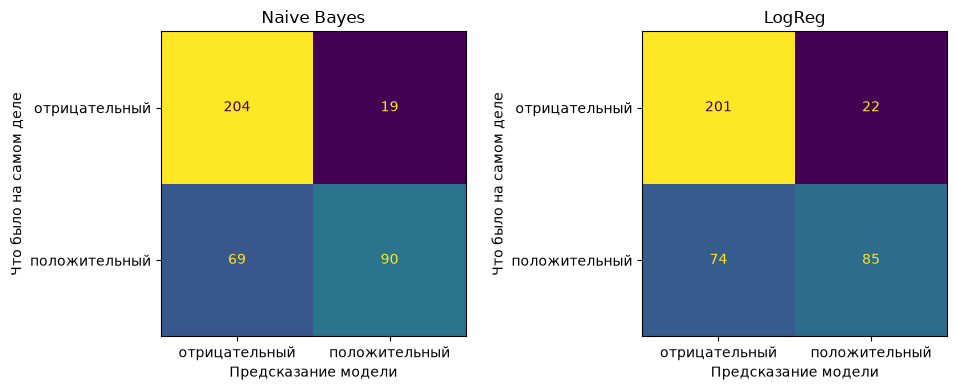

In [10]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

fitted = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)
    print("=====", name)
    print(classification_report(y_test, pred,
          target_names=["отрицательный", "положительный"], digits=3))

vocab = fitted["LogReg"].named_steps["tfidf"].get_feature_names_out()
print("Размерность признакового пространства (слов и пар слов):", len(vocab))
print("Документов в train:", len(X_train))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pipe) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pipe.predict(X_test), ax=ax, colorbar=False,
        display_labels=["отрицательный", "положительный"])
    ax.set_title(name)
    ax.set_xlabel("Предсказание модели")
    ax.set_ylabel("Что было на самом деле")
plt.tight_layout()
plt.show()

## Результаты на тестовой выборке (382 отзыва)
Размерность признакового пространства: **1 466** признаков (слов и пар слов) на 1 528 документов обучающей выборки. Параметры TF-IDF: слова и пары слов (ngram 1–2), min_df=3, max_df=0,9.

| Алгоритм | Accuracy | F1 (macro) | Отрицательные: precision / recall | Положительные: precision / recall |
|---|---|---|---|---|
| Naive Bayes | 0,770 | 0,747 | 0,747 / 0,915 | 0,826 / 0,566 |
| Логистическая регрессия | 0,749 | 0,723 | 0,731 / 0,901 | 0,794 / 0,535 |

Для сравнения: если всегда отвечать «отрицательный», accuracy составит 58,4% (223 из 382), поэтому 75–77% означает, что модели действительно что-то выучили. Оба алгоритма хорошо находят отрицательные отзывы (recall выше 0,90), но пропускают почти половину положительных (recall 0,54–0,57): положительные отзывы часто содержат жалобы или пожелания, а отрицательный класс в корпусе больше (58%). Результаты на тесте согласуются с кросс-валидацией: Naive Bayes снова немного впереди.

In [11]:
coef = fitted["LogReg"].named_steps["model"].coef_[0]
order = np.argsort(coef)
print("Сильнее всего указывают на ОТРИЦАТЕЛЬНЫЙ отзыв:", [vocab[i] for i in order[:15]])
print("Сильнее всего указывают на ПОЛОЖИТЕЛЬНЫЙ отзыв:", [vocab[i] for i in order[-15:][::-1]])

Сильнее всего указывают на ОТРИЦАТЕЛЬНЫЙ отзыв: ['не', 'интернет', 'вечно', 'плохой', 'ужасный', 'вообще', 'время', 'поддержка', 'глючить', 'сом', 'оператор', 'деньга', 'иштебей', 'сервер', 'не советовать']
Сильнее всего указывают на ПОЛОЖИТЕЛЬНЫЙ отзыв: ['хороший', 'спасибо', 'очень', 'отлично', 'удобный', 'хорошо', 'удобно', 'супер', 'классно', 'отличный', 'норма', 'минус', 'добавить', 'мбанк', 'всё']


## Какие слова определяют решение (коэффициенты логистической регрессии)
Отрицательный отзыв: «не», «вечно», «плохой», «ужасный», «вообще», «глючить», «не советовать», «иштебей» (по-кыргызски «не работает»), а также тематические слова «интернет», «оператор», «сервер», «поддержка», «деньга», «сом» — о них пишут в основном в жалобах.
Положительный отзыв: «хороший», «спасибо», «отлично», «удобный», «супер», «классно», «норма».

Выводы: (1) отрицание «не» оказалось самым сильным признаком отрицательного класса, значит, решение сохранить его при удалении стоп-слов было верным; (2) кыргызское «иштебей» попало в значимые слова, то есть модель частично использует кыргызские слова; (3) слова «минус» и «добавить» оказались признаками положительного класса: пользователи, ставящие 4–5 звёзд, часто пишут конструктивные замечания («хорошо, но добавьте...»). Модель выучила особенность разметки по звёздам, а не только тональность текста; (4) слово «мбанк» связано с положительным классом, то есть на модель влияет и название приложения.

In [12]:
BEST = "LogReg"    # или "Naive Bayes"

pred = fitted[BEST].predict(X_test)
proba = fitted[BEST].predict_proba(X_test)[:, 1]

res = df.loc[X_test.index, ["text", "score", "label"]].copy()
res["pred"] = pred
res["proba_pos"] = proba.round(2)
errors = res[res["label"] != res["pred"]]
print("Ошибок:", len(errors), "из", len(res))

errors.sample(8, random_state=1)

Ошибок: 96 из 382


,text,score,label,pred,proba_pos
1566,здравствуйте дорогая компания мой о!я бы хотел сообщить о неполадках о том что не получаются отключать некоторые тар...,4,1,0,0.35
567,сырое приложение,4,1,0,0.46
920,класно но один нюанс,5,1,0,0.46
707,бомба банк,4,1,0,0.49
1728,"Здравствуйте предложение хорошое, много чего можно оплатить. Но одно остаётся самым не приятным минусом, авто оплата...",4,1,0,0.42
692,"Здравствуйте! я бы хотел сказать чтобы вы улучшили систему защиты,и постарались как можно хорошо защитить наши средс...",4,1,0,0.25
1842,обслуживание моментальное и качественно,5,1,0,0.39
864,почему у меня окуу китеби не работает,5,1,0,0.16


## Разбор ошибок модели
Разбор сделан для логистической регрессии (у неё можно посмотреть коэффициенты и вероятности). Ошибок: 96 из 382. Все показанные ниже примеры: положительный отзыв (4–5 звёзд), предсказан отрицательный.

1. «здравствуйте дорогая компания мой о!я бы хотел сообщить о неполадках ...» (4 звезды, вероятность положительного 0,35). Текст — жалоба на неполадки. Гипотеза: шум разметки; модель по тексту поступила разумно, ошибочной скорее является метка.
2. «сырое приложение» (4 звезды, 0,46). Гипотеза: то же, текст по смыслу отрицательный, но оценка 4. Кроме того, текст из двух слов даёт модели очень мало информации.
3. «класно но один нюанс» (5 звёзд, 0,46). Гипотеза: слово написано с опечаткой («класно»), поэтому не совпало с «классно» из словаря модели, а «но один нюанс» указывает на оговорку. Вероятность близка к границе 0,5.
4. «бомба банк» (4 звезды, 0,49). Гипотеза: сленговая похвала, слово «бомба» редкое и почти не встречалось в обучающих данных.
5. «предложение хорошее, много чего можно оплатить. Но одно остаётся самым не приятным минусом, авто оплата...» (4 звезды, 0,42). Гипотеза: смешанный отзыв: сначала похвала, потом критика; «не» и «минус» тянут оценку в отрицательную сторону, хотя автор в итоге поставил 4.
6. «я бы хотел сказать чтобы вы улучшили систему защиты...» (4 звезды, 0,25). Гипотеза: пожелание без явных оценочных слов; смысл («улучшите») модель по отдельным словам понять не может.
7. «обслуживание моментальное и качественно» (5 звёзд, 0,39). Гипотеза: настоящая ошибка модели: отзыв положительный, но слова «моментальное» и «качественно» редкие и могли не попасть в словарь (min_df=3).
8. «почему у меня окую китеби не работает» (5 звёзд, 0,16). Гипотеза: отзыв со смесью кыргызских и русских слов; русское «не работает» тянет в отрицательную сторону, и текст по смыслу действительно жалоба, поэтому здесь скорее ошибка разметки (5 звёзд).

Доля верных ответов на отзывах с буквами ө/ү/ң: 0,545 (6 из 11), на остальных 0,755. Выборка из 11 отзывов слишком мала для уверенного вывода, но результат согласуется с тем, что русскоязычный пайплайн хуже работает на кыргызском тексте.

In [13]:
res["kg"] = res["text"].str.contains("[өүңӨҮҢ]", regex=True)
res.assign(correct=(res["label"] == res["pred"])).groupby("kg")["correct"].agg(["mean", "count"])

,mean,count
kg,,
False,0.754717,371
True,0.545455,11


## Выводы
**1. Корпус и разметка.** Собрано 1 913 русско- и частично кыргызскоязычных отзывов на приложения MBank и O! (58% отрицательных, 42% положительных). Разметка автоматическая по оценке пользователя, что даёт шум: 4–5 звёзд часто ставят вместе с жалобой.
**2. Предобработка.** Нижний регистр, токенизация, удаление стоп-слов (с сохранением отрицаний и оценочных слов), лемматизация, TF-IDF по словам и парам слов (1 466 признаков). Векторизатор обучается только на обучающей части.
**3. Сравнение алгоритмов.** Naive Bayes (accuracy 0,770, F1 macro 0,747 на тесте) и логистическая регрессия (0,749 и 0,723) близки по качеству: разница меньше разброса между фолдами кросс-валидации. Оба заметно лучше простого ответа «всегда отрицательный» (58,4%).
**4. Главная слабость.** Положительные отзывы находятся плохо (recall 0,54–0,57), потому что они часто содержат жалобы и пожелания; модели ошибаются в основном именно так.
**5. Ограничения.** Разметка по звёздам, короткие тексты (медиана 10 слов), малый размер корпуса, кыргызский язык обрабатывается русским пайплайном (на 11 кыргызских отзывах теста верно определено 6, выборка слишком мала для вывода), сарказм и смешанные отзывы.
**6. Что можно улучшить.** Проверить часть разметки вручную, составить кыргызские стоп-слова и правила нормализации, собрать больше данных, учесть опечатки.

In [14]:
import pandas as pd
from google_play_scraper import reviews, Sort

COLLECT = False   # True: заново скачать отзывы из Google Play (числа в работе изменятся)

if COLLECT:
    APPS = {
        "mbank": "com.maanavan.mb_kyrgyzstan",
        "o_nurtelecom": "kg.o.nurtelecom",
    }
    rows = []
    for name, app_id in APPS.items():
        for score in [1, 2, 4, 5]:
            result, _ = reviews(app_id, lang="ru", country="kg",
                                sort=Sort.NEWEST, count=300, filter_score_with=score)
            for r in result:
                rows.append({"app": name, "text": r["content"], "score": r["score"], "date": r["at"]})
            print(name, "оценка", score, "->", len(result))
    raw = pd.DataFrame(rows)
    print("Всего собрано:", len(raw))

In [15]:
if COLLECT:
    df = raw.copy()
    df = df.dropna(subset=["text"])
    df = df.drop_duplicates(subset="text")
    df = df[df["text"].str.contains("[а-яА-ЯёЁ]", regex=True)]
    df = df[df["text"].str.len() >= 10]
    df["label"] = (df["score"] >= 4).astype(int)
    df = df.reset_index(drop=True)
else:
    df = pd.read_csv("../data/reviews.csv")

print("Документов в корпусе:", len(df))
print(df["label"].value_counts())
print(df["app"].value_counts())

Документов в корпусе: 1913
label
0    1114
1     799
Name: count, dtype: int64
app
mbank           989
o_nurtelecom    924
Name: count, dtype: int64


In [16]:
if COLLECT:
    df = raw.copy()
    df = df.dropna(subset=["text"])
    df = df.drop_duplicates(subset="text")
    df = df[df["text"].str.contains("[а-яА-ЯёЁ]", regex=True)]
    df = df[df["text"].str.len() >= 10]
    df["label"] = (df["score"] >= 4).astype(int)
    df = df.reset_index(drop=True)
else:
    df = pd.read_csv("../data/reviews.csv")

print("Документов в корпусе:", len(df))
print(df["label"].value_counts())
print(df["app"].value_counts())

Документов в корпусе: 1913
label
0    1114
1     799
Name: count, dtype: int64
app
mbank           989
o_nurtelecom    924
Name: count, dtype: int64
